# Más información sobre **Numpy**

In [2]:
import numpy as np
import matplotlib.pyplot as plt

## Productos entre arrays y productos vectoriales

In [2]:
# Creamos arrays unidimensionales (vectores) y bidimensionales (matrices)
v1 = np.array([2, 3, 4])
v2 = np.array([1, 1, 1])
A = np.arange(1,13,2).reshape(2, 3)           # Matriz de 2x3
B = np.linspace(0.5,11.5,12).reshape(3, 4)    # Matriz de 3x4

In [3]:
print(A)

[[ 1  3  5]
 [ 7  9 11]]


In [4]:
print(B)

[[ 0.5  1.5  2.5  3.5]
 [ 4.5  5.5  6.5  7.5]
 [ 8.5  9.5 10.5 11.5]]


In [5]:
print(v1*v2)

[2 3 4]


In [7]:
print(A)
print(v1)

[[ 1  3  5]
 [ 7  9 11]]
[2 3 4]


In [8]:
print(A.shape)
print(v1.shape)

(2, 3)
(3,)


In [6]:
print(A*v1)

[[ 2  9 20]
 [14 27 44]]


In [9]:
print(A*B)

ValueError: operands could not be broadcast together with shapes (2,3) (3,4) 

Los productos se realizan "elemento a elemento", si queremos obtener "productos internos" o productos entre matrices (o matrices y vectores)

In [10]:
print(v1, '.', v2, '=', np.dot(v1, v2))

[2 3 4] . [1 1 1] = 9


In [11]:
print( A, 'x', v1, '=', np.dot(A, v1))

[[ 1  3  5]
 [ 7  9 11]] x [2 3 4] = [31 85]


In [12]:
print(A.shape, B.shape)

(2, 3) (3, 4)


In [13]:
print( 'A x B = \n', np.dot(A, B) )

A x B = 
 [[ 56.5  65.5  74.5  83.5]
 [137.5 164.5 191.5 218.5]]


In [15]:
print(B,B.shape)
print(B.T,B.T.shape)

[[ 0.5  1.5  2.5  3.5]
 [ 4.5  5.5  6.5  7.5]
 [ 8.5  9.5 10.5 11.5]] (3, 4)
[[ 0.5  4.5  8.5]
 [ 1.5  5.5  9.5]
 [ 2.5  6.5 10.5]
 [ 3.5  7.5 11.5]] (4, 3)


In [16]:
print( 'B^t x A^t =\n ',np.dot(B.T, A.T))

B^t x A^t =
  [[ 56.5 137.5]
 [ 65.5 164.5]
 [ 74.5 191.5]
 [ 83.5 218.5]]


Además, el módulo numpy.linalg incluye otras funcionalidades como determinantes, normas, determinación de autovalores y autovectores, descomposiciones, etc.

## Broadcasting: operaciones entre arrays de distintas formas

La biblioteca `numpy` puede, en algunos casos, operar con arrays de distintas formas (_shapes_). Esta regla se llama **broadcasting**.

La idea es que algunas dimensiones se pueden "estirar" para hacer una operación elemento a elemento sin escribir bucles explícitos. Esto no significa que siempre se copien los datos: muchas veces `numpy` sólo interpreta las dimensiones de otra manera para poder realizar la operación.

La regla práctica es comparar las dimensiones desde la derecha. 

Dos dimensiones son compatibles si 
- son iguales, 
- si una de ellas vale `1`, o 
- si una de ellas no existe.

In [7]:
a = np.array([1, 2, 3])

print('a:', a)
print('a.shape:', a.shape)

print('a + 10:', a + 10)


a: [1 2 3]
a.shape: (3,)
a + 10: [11 12 13]


En este caso, el escalar `10` se comporta como si tuviera la misma forma que `a`:

In [18]:
A = np.array([[1, 2, 3],
              [4, 5, 6]])

v = np.array([10, 20, 30])

print('A.shape:', A.shape)
print('v.shape:', v.shape)
print(A + v)

A.shape: (2, 3)
v.shape: (3,)
[[11 22 33]
 [14 25 36]]


Aquí `v` tiene forma `(3,)`. Al compararla con `A`, que tiene forma `(2, 3)`, la última dimensión coincide. Entonces `numpy` aplica el vector a cada fila de `A`.

Podemos pensar la compatibilidad así:

```text
A.shape  -> (2, 3)
v.shape  ->    (3,)
resultado -> (2, 3)
```

Si queremos sumar un valor distinto a cada fila, necesitamos que el vector tenga forma `(2, 1)`. Para eso podemos usar `reshape()`:

In [19]:
fila = np.array([100, 200]).reshape(2, 1)

print('A:',A)
print('A.shape:', A.shape)
print('fila.shape:', fila.shape)
print(A + fila)

A: [[1 2 3]
 [4 5 6]]
A.shape: (2, 3)
fila.shape: (2, 1)
[[101 102 103]
 [204 205 206]]


La forma `(2, 1)` se puede combinar con `(2, 3)`: la primera dimensión coincide y la segunda, que vale `1`, se puede estirar.

```text
A.shape     -> (2, 3)
fila.shape  -> (2, 1)
resultado   -> (2, 3)
```

También podemos crear dimensiones nuevas con `None`, que es equivalente a `np.newaxis`. 
> Esta notación es muy útil porque aparece una idea parecida en **PyTorch** con `unsqueeze()`.

In [21]:
x = np.array([1, 2, 3])
y = np.array([10, 20])

print('x.shape:', x.shape)
print('x[None, :].shape:', x[None, :].shape)
print('y.shape:', y.shape)
print('y[:, None].shape:', y[:, None].shape)

x.shape: (3,)
x[None, :].shape: (1, 3)
y.shape: (2,)
y[:, None].shape: (2, 1)


In [22]:
print(x+y)

ValueError: operands could not be broadcast together with shapes (3,) (2,) 

In [23]:
print(y[:, None] + x[None, :])
print('resultado:', (y[:, None] + x[None, :]).shape)

[[11 12 13]
 [21 22 23]]
resultado: (2, 3)


En este caso se combinan las formas `(2, 1)` y `(1, 3)`, y el resultado tiene forma `(2, 3)`.

```text
y[:, None].shape -> (2, 1)
x[None, :].shape -> (1, 3)
resultado         -> (2, 3)
```

Un uso muy común en ciencia de datos y aprendizaje automático es normalizar columnas. Supongamos que cada fila es una observación y cada columna es una variable:

In [25]:
X = np.array([[1.0, 10.0, 100.0],
              [2.0, 20.0, 200.0],
              [3.0, 30.0, 300.0],
              [4.0, 40.0, 400.0]])

media = X.mean(axis=0)
desvio = X.std(axis=0)

print('X.shape:', X.shape)
print('media.shape:', media.shape)
print('desvio.shape:', desvio.shape)
print('media:', media)
print('desvio:', desvio)

X.shape: (4, 3)
media.shape: (3,)
desvio.shape: (3,)
media: [  2.5  25.  250. ]
desvio: [  1.11803399  11.18033989 111.80339887]


In [26]:
X_norm = (X - media) / desvio

print(X_norm)
print('medias luego de normalizar:', X_norm.mean(axis=0))
print('desvios luego de normalizar:', X_norm.std(axis=0))

[[-1.34164079 -1.34164079 -1.34164079]
 [-0.4472136  -0.4472136  -0.4472136 ]
 [ 0.4472136   0.4472136   0.4472136 ]
 [ 1.34164079  1.34164079  1.34164079]]
medias luego de normalizar: [0. 0. 0.]
desvios luego de normalizar: [1. 1. 1.]


La resta `X - media` funciona porque `X` tiene forma `(4, 3)` y `media` tiene forma `(3,)`. Es decir: se resta la media de cada columna a todas las filas.

> Esta misma lógica aparece en **PyTorch** cuando trabajamos con tensores. Si `X` tiene forma `(batch, features)` y `media` tiene forma `(features,)`, la operación se aplica automáticamente a todos los elementos del batch.

## Copias de arrays y vistas

Para poder controlar el uso de memoria y su optimización, **Numpy** no siempre crea un nuevo vector al realizar operaciones. Por ejemplo cuando seleccionamos una parte de un array usando la notación con ":" (*slicing*) devuelve algo que parece un nuevo array pero que en realidad es una nueva vista del mismo array. Lo mismo ocurre con el método `reshape()`

In [27]:
x0 = np.linspace(1,24,24)
print(x0)

[ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.
 19. 20. 21. 22. 23. 24.]


In [28]:
y0 = x0[::2]
print(y0)

[ 1.  3.  5.  7.  9. 11. 13. 15. 17. 19. 21. 23.]


El atributo `base` nos da acceso al objeto que tiene los datos. Por ejemplo, en este caso:

In [29]:
print(x0.base)

[ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.
 19. 20. 21. 22. 23. 24.]


In [30]:
print(y0.base)

[ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.
 19. 20. 21. 22. 23. 24.]


In [31]:
y0.base is x0.base

True

In [32]:
type(x0), type(y0)

(numpy.ndarray, numpy.ndarray)

In [33]:
y0.size, x0.size

(12, 24)

In [34]:
y0[1] = -1
print(x0)

[ 1.  2. -1.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.
 19. 20. 21. 22. 23. 24.]


In [35]:
x0.base

array([ 1.,  2., -1.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13.,
       14., 15., 16., 17., 18., 19., 20., 21., 22., 23., 24.])

In [36]:
x0.strides, y0.strides

((8,), (16,))

En este ejemplo, el array `y0` está basado en `x0`, o --lo que es lo mismo-- el objeto base de `y0` es `x0`. Por lo tanto, al modificar uno, se modifica el otro.

Las funciones `reshape` y `transpose` también devuelven **vistas** del array original en lugar de una nueva copia

In [37]:
x0 = np.linspace(1,24,24)
print(x0)
x1 = x0.reshape(6,-1)

[ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.
 19. 20. 21. 22. 23. 24.]


In [38]:
print(x1)

[[ 1.  2.  3.  4.]
 [ 5.  6.  7.  8.]
 [ 9. 10. 11. 12.]
 [13. 14. 15. 16.]
 [17. 18. 19. 20.]
 [21. 22. 23. 24.]]


In [39]:
print(x1.base is x0.base)

True


In [40]:
x2 = x1.transpose()
print(x2.base is x0.base)

True


In [41]:
x2

array([[ 1.,  5.,  9., 13., 17., 21.],
       [ 2.,  6., 10., 14., 18., 22.],
       [ 3.,  7., 11., 15., 19., 23.],
       [ 4.,  8., 12., 16., 20., 24.]])

In [42]:
x2.strides, x1.strides

((8, 32), (32, 8))

Las "vistas" son referencias al mismo conjunto de datos, pero la información respecto al objeto puede ser diferente. Por ejemplo en el anterior `x0`, `x1` y `x` son diferentes objetos pero con los mismos datos (no sólo iguales)

In [43]:
print(x1.base is x0.base)
print(x2.base is x0.base)
print(x0.shape, x0.strides, x0.dtype)
print(x1.shape, x1.strides, x1.dtype)
print(x2.shape, x2.strides, x2.dtype)

True
True
(24,) (8,) float64
(6, 4) (32, 8) float64
(4, 6) (8, 32) float64


Los datos en los tres objetos están compartidos:

In [44]:
print('original')
print('x2 =',x2)
x0[-1] =-1
print('x0 =',x0)

original
x2 = [[ 1.  5.  9. 13. 17. 21.]
 [ 2.  6. 10. 14. 18. 22.]
 [ 3.  7. 11. 15. 19. 23.]
 [ 4.  8. 12. 16. 20. 24.]]
x0 = [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.
 19. 20. 21. 22. 23. -1.]


In [45]:
print('cambiado')
print('x2 =',x2)

cambiado
x2 = [[ 1.  5.  9. 13. 17. 21.]
 [ 2.  6. 10. 14. 18. 22.]
 [ 3.  7. 11. 15. 19. 23.]
 [ 4.  8. 12. 16. 20. -1.]]


In [46]:
print('x1 =',x1)

x1 = [[ 1.  2.  3.  4.]
 [ 5.  6.  7.  8.]
 [ 9. 10. 11. 12.]
 [13. 14. 15. 16.]
 [17. 18. 19. 20.]
 [21. 22. 23. -1.]]


## Indexado avanzado 


### nonzero

La función `nonzero()` de Numpy devuelve una *tupla* de arrays, una por dimensión, que contiene los índices de los elementos no nulos

In [47]:
# El método copy() crea un nuevo array con los mismos valores que el original
arr4 = x1.copy()
arr4[1,:2] = arr4[2,2:] = 0
arr4

array([[ 1.,  2.,  3.,  4.],
       [ 0.,  0.,  7.,  8.],
       [ 9., 10.,  0.,  0.],
       [13., 14., 15., 16.],
       [17., 18., 19., 20.],
       [21., 22., 23., -1.]])

In [48]:
# Vemos que arr2 no se modifica al modificar arr4.
x1

array([[ 1.,  2.,  3.,  4.],
       [ 5.,  6.,  7.,  8.],
       [ 9., 10., 11., 12.],
       [13., 14., 15., 16.],
       [17., 18., 19., 20.],
       [21., 22., 23., -1.]])

In [49]:
np.nonzero(arr4)

(array([0, 0, 0, 0, 1, 1, 2, 2, 3, 3, 3, 3, 4, 4, 4, 4, 5, 5, 5, 5]),
 array([0, 1, 2, 3, 2, 3, 0, 1, 0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3]))

In [ ]:
np.transpose(arr4.nonzero())

In [ ]:
arr4[arr4.nonzero()]

In [ ]:
arr4

In [ ]:
arr4[([0,0], [2,3])]

### Indexado con secuencias de índices

Consideremos un vector simple, y elijamos algunos de sus elementos

In [51]:
x = np.linspace(0,3,7)
x

array([0. , 0.5, 1. , 1.5, 2. , 2.5, 3. ])

In [52]:
# Standard slicing
v1=x[1::2]
v1

array([0.5, 1.5, 2.5])

Esta es la manera simple de seleccionar elementos de un array, y como vimos lo que se obtiene es una vista del mismo array. **Numpy** permite además seleccionar partes de un array usando otro array de índices:

In [55]:
# Array Slicing con índices ind
i1 = np.array([1,3,-1,0])   
v2 = x[i1]

In [57]:
print(x)
print(x[i1])

[0.  0.5 1.  1.5 2.  2.5 3. ]
[0.5 1.5 3.  0. ]


In [58]:
print(v1.base is x.base)
print(v2.base is x.base)

True
False


In [ ]:
x[[1,2,-1]]

Los índices negativos funcionan en exactamente la misma manera que en el caso simple. 

Es importante notar que cuando se usan arrays índices, lo que se obtiene es un nuevo array (no una vista), y este nuevo array tiene las dimensiones (`shape`) del array de índices

In [ ]:
i2 = np.array([[1,0],[2,1]])
v3= x[i2]
print(x)
print(v3)
print('x  shape:', x.shape)
print('v3 shape:', v3.shape)

In [ ]:
x.base is v3.base

## Enumerate para `ndarrays`

Para iterables en **Python** existe la función enumerate que devuelve una tupla con el índice y el valor. En **Numpy** existe un iterador multidimensional llamado `ndenumerate()`

In [ ]:
print(arr4)

In [ ]:
for (i,j), x in np.ndenumerate(arr4):
  print(f'x[{i},{j}]-> {x}')

## Vectorización de funciones escalares

Si bien en **Numpy** las funciones están vectorizadas, hay ocasiones en que las funciones son el resultado de una simulación, optimización, integración u otro cálculo complejo, y si bien la paralelización puede ser trivial, el cálculo debe ser realizado para cada valor de algún parámetro y no puede ser realizado directamente con un vector. Para ello existe la función `vectorize()`. Veamos un ejemplo, calculando la función *coseno()* como la integral del *seno()*

In [59]:
def my_trapz(f, a, b):
  x = np.linspace(a,b,200)
  y = f(x)
  return ((y[1:]+y[:-1])*(x[1:]-x[:-1])).sum()/2

In [60]:
def mi_cos(t):
  return 1-my_trapz(np.sin, 0, t)

In [61]:
mi_cos(np.pi/4)

np.float64(0.7071071613775138)

que se compara bastante bien con el valor esperado del coseno:

In [62]:
np.cos(np.pi/4)

np.float64(0.7071067811865476)

Para calcular sobre un conjunto de datos:

In [66]:
x = np.linspace(0, np.pi, 30)
x

array([0.        , 0.10833078, 0.21666156, 0.32499234, 0.43332312,
       0.54165391, 0.64998469, 0.75831547, 0.86664625, 0.97497703,
       1.08330781, 1.19163859, 1.29996937, 1.40830016, 1.51663094,
       1.62496172, 1.7332925 , 1.84162328, 1.94995406, 2.05828484,
       2.16661562, 2.2749464 , 2.38327719, 2.49160797, 2.59993875,
       2.70826953, 2.81660031, 2.92493109, 3.03326187, 3.14159265])

In [64]:
print(mi_cos(x))

-28.99965617508409


Obtuvimos un valor único que claramente no puede ser el coseno de ningún ángulo. Si calculamos el coseno con el mismo argumento (vectorial) obtenemos un vector de valores como se espera:

In [65]:
print(np.cos(x))

[ 1.          0.99413796  0.97662056  0.94765317  0.90757542  0.85685718
  0.79609307  0.72599549  0.64738628  0.56118707  0.46840844  0.37013816
  0.26752834  0.161782    0.05413891 -0.05413891 -0.161782   -0.26752834
 -0.37013816 -0.46840844 -0.56118707 -0.64738628 -0.72599549 -0.79609307
 -0.85685718 -0.90757542 -0.94765317 -0.97662056 -0.99413796 -1.        ]


Si el cálculo fuera más complejo y no tuviéramos la posibilidad de realizarlo en forma vectorial, debemos realizar una iteración llamando a esta función en cada paso:

In [67]:
y = []
for xx in x:
  y.append(mi_cos(xx))
print(np.array(y))

[ 1.          0.99413796  0.97662056  0.94765318  0.90757546  0.85685726
  0.79609325  0.72599582  0.64738684  0.56118794  0.46840975  0.37014004
  0.26753094  0.16178549  0.05414349 -0.05413305 -0.16177465 -0.26751929
 -0.37012719 -0.46839535 -0.56117164 -0.64736834 -0.72597486 -0.7960696
 -0.85683076 -0.90754598 -0.94762066 -0.97658497 -0.99409935 -0.99995846]


In [68]:
y = np.zeros(x.size)
for i,xx in enumerate(x):
  y[i] = mi_cos(xx)

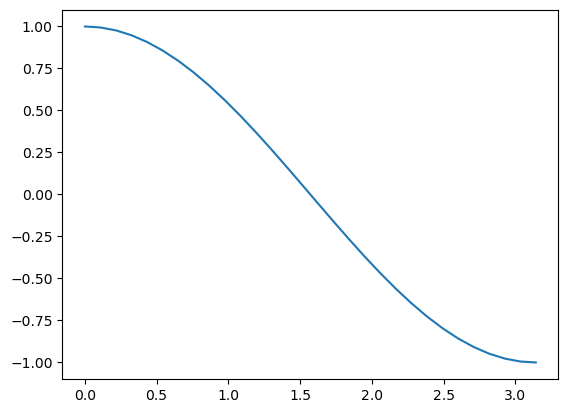

In [71]:
plt.plot(x,y)

Como conveniencia, para evitar tener que hacer explícitamente el bucle `for` existe la función `vectorize`, que toma como argumento a una función que toma y devuelve escalares, y retorna una función equivalente que acepta arrays:

In [69]:
coseno = np.vectorize(mi_cos)

In [70]:
coseno

In [73]:
coseno(x)

array([ 1.        ,  0.99413796,  0.97662056,  0.94765318,  0.90757546,
        0.85685726,  0.79609325,  0.72599582,  0.64738684,  0.56118794,
        0.46840975,  0.37014004,  0.26753094,  0.16178549,  0.05414349,
       -0.05413305, -0.16177465, -0.26751929, -0.37012719, -0.46839535,
       -0.56117164, -0.64736834, -0.72597486, -0.7960696 , -0.85683076,
       -0.90754598, -0.94762066, -0.97658497, -0.99409935, -0.99995846])

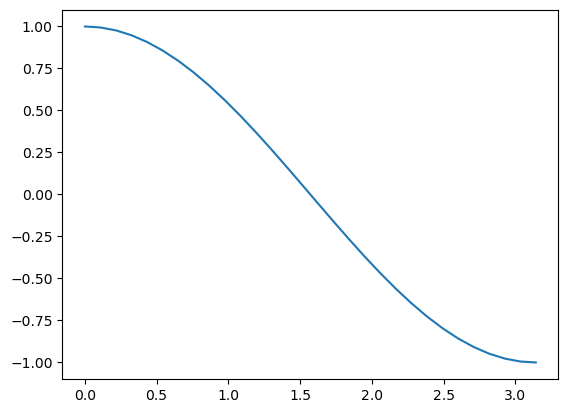

In [72]:
plt.plot(x, coseno(x), '-')

-----

## Ejercicios 09 (a)

1. Dado un array `a` de números, creado por ejemplo usando:
   ```python
   a = np.random.uniform(size=100)
   ```
   Crear una función que encuentre el número más cercano a un número escalar dado que va a tomar como argumento (por ejemplo x=0.5) utilizando métodos de arrays.

   ```python
   cercano = mas_cercano(a, x)
   ```

   Puede buscar, entre los métodos de `arrays`, los métodos `argmin()`, `argmax()`, `min()`, `max()`
   
-----

.